Data formation (rows, cols): (705, 13)

Column names:
 ['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score', 'Relationship_Status', 'Conflicts_Over_Social_Media', 'Addicted_Score']


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7



Check for missing values ​​in each column:
 Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Country                         0
Avg_Daily_Usage_Hours           0
Most_Used_Platform              0
Affects_Academic_Performance    0
Sleep_Hours_Per_Night           0
Mental_Health_Score             0
Relationship_Status             0
Conflicts_Over_Social_Media     0
Addicted_Score                  0
dtype: int64

 Data Types:

Student_ID                        int64
Age                               int64
Gender                           object
Academic_Level                   object
Country                          object
Avg_Daily_Usage_Hours           float64
Most_Used_Platform               object
Affects_Academic_Performance     object
Sleep_Hours_Per_Night           float64
Mental_Health_Score               int64
Relationship_Status              object
Conflicts_Over_Social_Media       int64
Addic

,count,mean,std,min,25%,50%,75%,max
Student_ID,705.0,353.000000,203.660256,1.0,177.0,353.0,529.0,705.0
Age,705.0,20.659574,1.399217,18.0,19.0,21.0,22.0,24.0
Avg_Daily_Usage_Hours,705.0,4.918723,1.257395,1.5,4.1,4.8,5.8,8.5
Sleep_Hours_Per_Night,705.0,6.868936,1.126848,3.8,6.0,6.9,7.7,9.6
Mental_Health_Score,705.0,6.226950,1.105055,4.0,5.0,6.0,7.0,9.0
Conflicts_Over_Social_Media,705.0,2.849645,0.957968,0.0,2.0,3.0,4.0,5.0
Addicted_Score,705.0,6.436879,1.587165,2.0,5.0,7.0,8.0,9.0



Distribution of values ​​for some categorical columns (Top counts):


--- Gender ---
Gender
Female    353
Male      352
Name: count, dtype: int64

--- Academic_Level ---
Academic_Level
Undergraduate    353
Graduate         325
High School       27
Name: count, dtype: int64

--- Most_Used_Platform ---
Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
WhatsApp      54
Twitter       30
LinkedIn      21
WeChat        15
Snapchat      13
VKontakte     12
LINE          12
KakaoTalk     12
YouTube       10
Name: count, dtype: int64

--- Affects_Academic_Performance ---
Affects_Academic_Performance
Yes    453
No     252
Name: count, dtype: int64

--- Relationship_Status ---
Relationship_Status
Single             384
In Relationship    289
Complicated         32
Name: count, dtype: int64


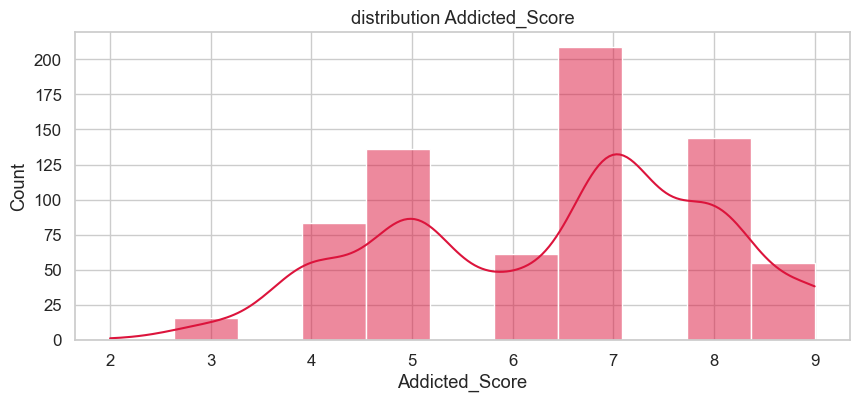

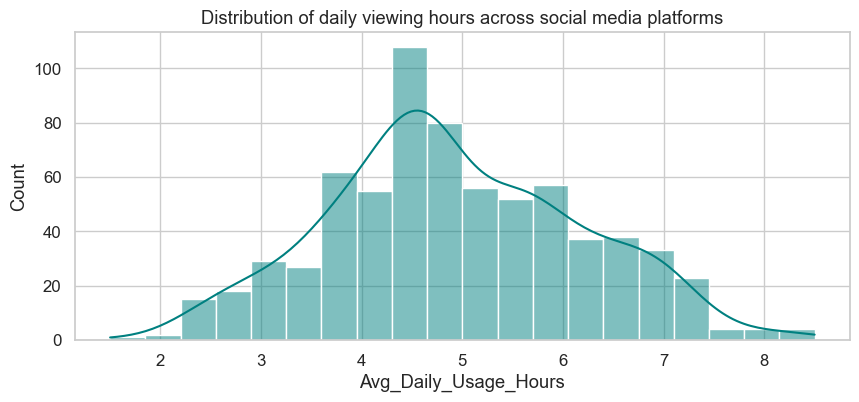

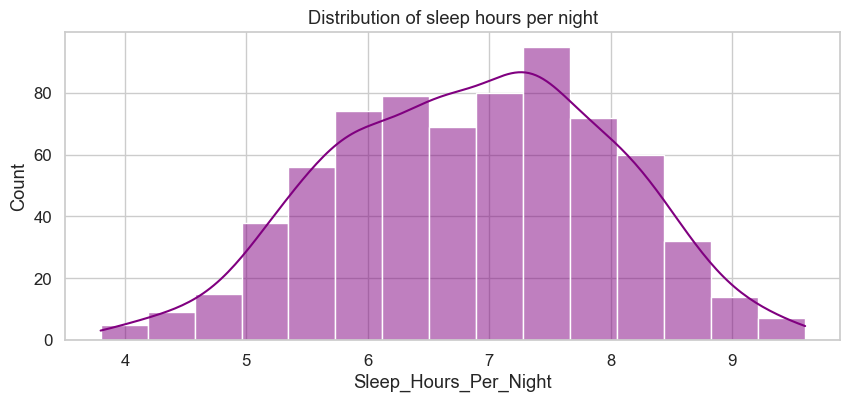

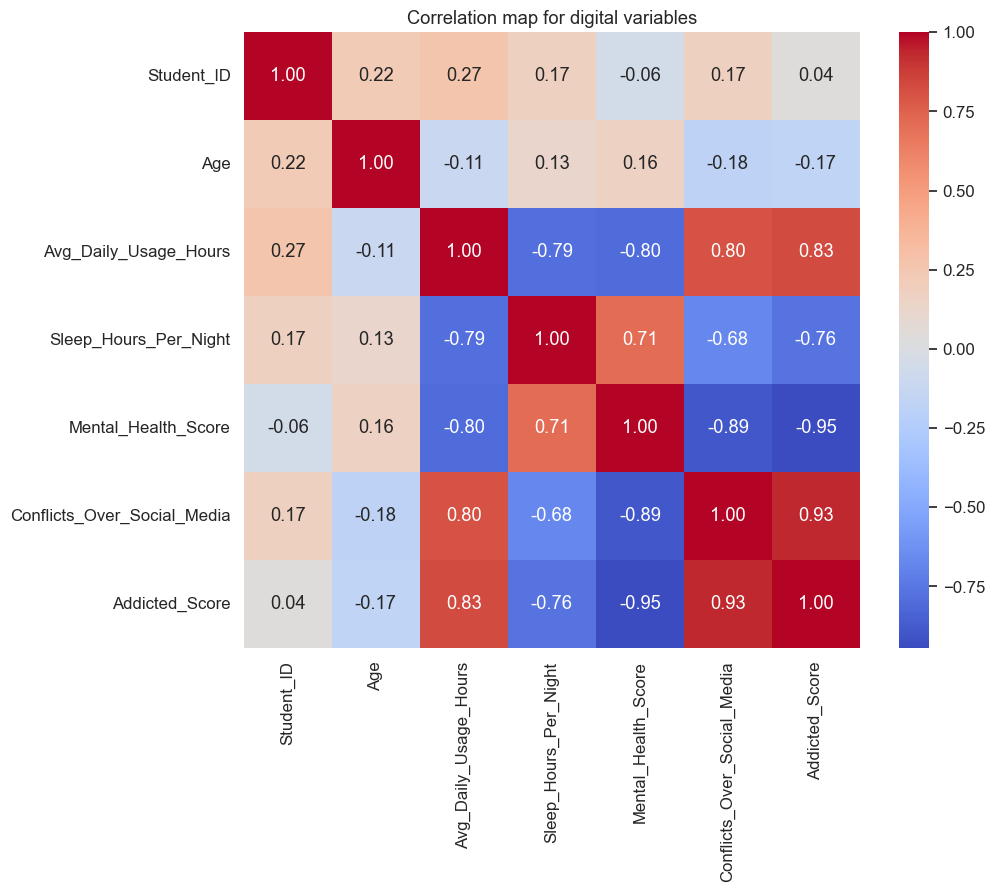

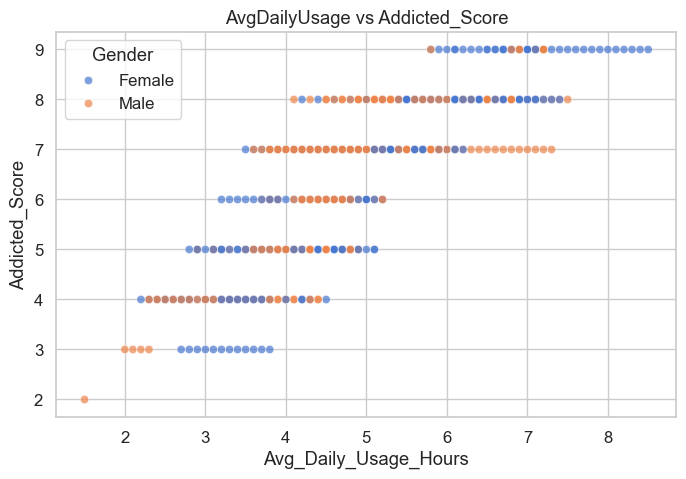


Distribution of addiction levels:
 Addiction_Level
High        408
Moderate    280
Low          17
Name: count, dtype: int64
Pearson correlation between Addicted_Score and Avg_Daily_Usage_Hours: r=0.832, p-value=4.702e-182
Pearson correlation between Addicted_Score and Sleep_Hours_Per_Night: r=-0.765, p-value=2.164e-136
Pearson correlation between Addicted_Score and Mental_Health_Score: r=-0.945, p-value=0.000e+00

ANOVA Addicted_Score by Gender: F=1.740, p=1.875e-01


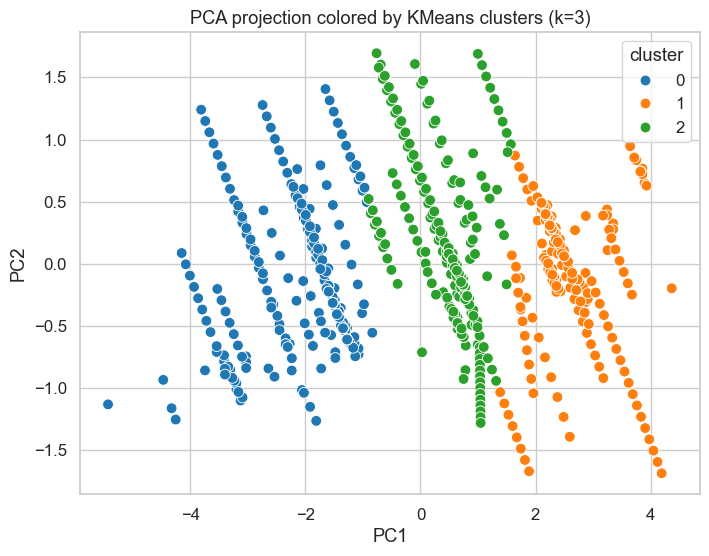


Summary of averages for each cluster:


,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Conflicts_Over_Social_Media,Addicted_Score
cluster,,,,,
0.0,3.807836,7.832090,7.399254,1.854478,4.679104
1.0,6.424599,5.595187,4.994652,4.032086,8.251337
2.0,4.983200,6.789200,5.892000,3.032000,6.964000



Accuracy: 0.9716312056737588

Classification Report:
               precision    recall  f1-score   support

        High       0.95      1.00      0.98        82
         Low       1.00      1.00      1.00         3
    Moderate       1.00      0.93      0.96        56

    accuracy                           0.97       141
   macro avg       0.98      0.98      0.98       141
weighted avg       0.97      0.97      0.97       141


Feature importances:
 Mental_Health_Score            0.445479
Conflicts_Over_Social_Media    0.278954
Sleep_Hours_Per_Night          0.155327
Avg_Daily_Usage_Hours          0.081423
Age                            0.038817
dtype: float64


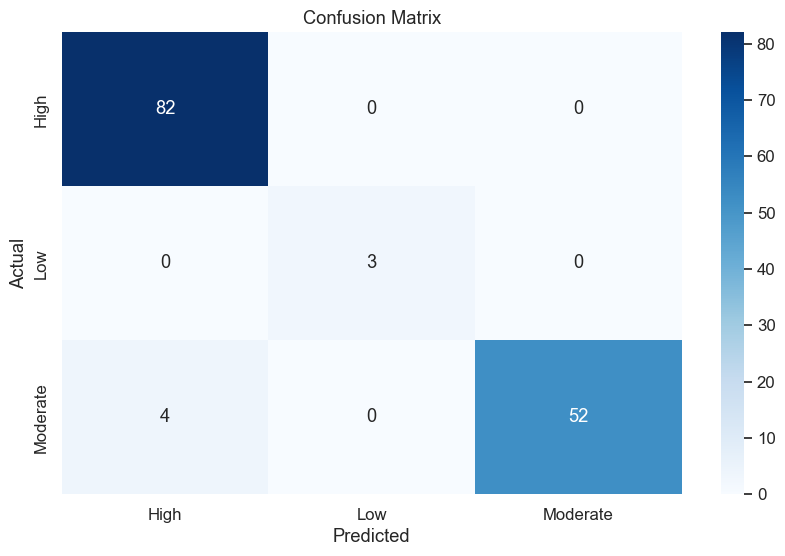

The form has been saved in rf_addiction_model.pkl

Summary and Recommendations:
- If the results show a strong correlation between usage time and the addiction scale, this would confirm the main hypothesis.
- More advanced tests: Use SHAP to interpret tree-based models, or employ advanced models like XGBoost.
- Study categorical variables: Do certain platforms increase the risk of addiction? Use ANOVA or chi-square tests.
- Propose interventions: Develop a predictive model for early warning (e.g., identifying students at high risk) and implement awareness/intervention programs.



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from scipy import stats
import pickle
import warnings
warnings.filterwarnings('ignore')
sns.set(style='whitegrid', palette='muted', font_scale=1.1, rc={'figure.figsize':(10,6)})

file_path = "D:\\Data Analysis Projects\\Students Social Media Addiction\\Students Social Media Addiction.csv"
df = pd.read_csv(file_path)  # قراءة الملف

print("Data formation (rows, cols):", df.shape)
print("\nColumn names:\n", df.columns.tolist())
display(df.head())   # عرض 5 صفوف أولى
print("\nCheck for missing values ​​in each column:\n", df.isnull().sum())
print("\n Data Types:\n")
print(df.dtypes)

df = df.copy()
df.drop_duplicates(inplace=True)

if df['Age'].dtype != 'int64':
    df['Age'] = df['Age'].astype(int)

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("\nDigital columns:", numeric_cols)
print("\nStatistical summary of the numerical columns:\n")
display(df[numeric_cols].describe().T)

print("\nDistribution of values ​​for some categorical columns (Top counts):\n")
for col in ['Gender','Academic_Level','Most_Used_Platform','Affects_Academic_Performance','Relationship_Status']:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts().head(20))

plt.figure(figsize=(10,4))
if 'Addicted_Score' in df.columns:
    sns.histplot(df['Addicted_Score'], bins=11, kde=True, color='crimson')
    plt.title('distribution Addicted_Score')
    plt.xlabel('Addicted_Score')
    plt.show()

plt.figure(figsize=(10,4))
if 'Avg_Daily_Usage_Hours' in df.columns:
    sns.histplot(df['Avg_Daily_Usage_Hours'], bins=20, kde=True, color='teal')
    plt.title('Distribution of daily viewing hours across social media platforms')
    plt.xlabel('Avg_Daily_Usage_Hours')
    plt.show()

plt.figure(figsize=(10,4))
if 'Sleep_Hours_Per_Night' in df.columns:
    sns.histplot(df['Sleep_Hours_Per_Night'], bins=15, kde=True, color='purple')
    plt.title('Distribution of sleep hours per night')
    plt.xlabel('Sleep_Hours_Per_Night')
    plt.show()

num = df.select_dtypes(include=[np.number])
corr = num.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation map for digital variables')
plt.show()

# علاقة مباشرة: ساعات الاستخدام اليومي مقابل مقياس الإدمان
if {'Avg_Daily_Usage_Hours','Addicted_Score'}.issubset(df.columns):
    plt.figure(figsize=(8,5))
    sns.scatterplot(x='Avg_Daily_Usage_Hours', y='Addicted_Score', hue='Gender' if 'Gender' in df.columns else None, data=df, alpha=0.7)
    plt.title('AvgDailyUsage vs Addicted_Score')
    plt.show()

def categorize_addiction(score):
    if score <= 3:
        return 'Low'
    elif score <= 6:
        return 'Moderate'
    else:
        return 'High'

if 'Addicted_Score' in df.columns:
    df['Addiction_Level'] = df['Addicted_Score'].apply(categorize_addiction)
    print("\nDistribution of addiction levels:\n", df['Addiction_Level'].value_counts())

if 'Addicted_Score' in df.columns:
    for col in ['Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Mental_Health_Score']:
        if col in df.columns:
            r, p = stats.pearsonr(df['Addicted_Score'], df[col])
            print(f"Pearson correlation between Addicted_Score and {col}: r={r:.3f}, p-value={p:.3e}")

    if 'Gender' in df.columns:
        groups = [group['Addicted_Score'].values for name, group in df.groupby('Gender')]
        f, p = stats.f_oneway(*groups)
        print(f"\nANOVA Addicted_Score by Gender: F={f:.3f}, p={p:.3e}")

features_for_clustering = ['Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Mental_Health_Score','Conflicts_Over_Social_Media','Addicted_Score']
features_for_clustering = [f for f in features_for_clustering if f in df.columns]

X_cluster = df[features_for_clustering].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
df.loc[X_cluster.index, 'cluster'] = clusters

plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=clusters, palette='tab10', s=60)
plt.title('PCA projection colored by KMeans clusters (k=3)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='cluster')
plt.show()

print("\nSummary of averages for each cluster:")
display(df.groupby('cluster')[features_for_clustering].mean())

if 'Addiction_Level' in df.columns:
    model_features = ['Age','Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Mental_Health_Score','Conflicts_Over_Social_Media']
    model_features = [c for c in model_features if c in df.columns]
    X = df[model_features].fillna(df[model_features].median())
    y = df['Addiction_Level']
    le = LabelEncoder()
    y_enc = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(X, y_enc, test_size=0.2, random_state=42, stratify=y_enc)
    clf = RandomForestClassifier(n_estimators=200, random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    print("\nAccuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))

    feat_imp = pd.Series(clf.feature_importances_, index=model_features).sort_values(ascending=False)
    print("\nFeature importances:\n", feat_imp)

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

    with open('rf_addiction_model.pkl','wb') as f:
        pickle.dump({'model':clf, 'label_encoder':le, 'features':model_features, 'scaler':scaler}, f)
    print("The form has been saved in rf_addiction_model.pkl")

summary = """
Summary and Recommendations:
- If the results show a strong correlation between usage time and the addiction scale, this would confirm the main hypothesis.
- More advanced tests: Use SHAP to interpret tree-based models, or employ advanced models like XGBoost.
- Study categorical variables: Do certain platforms increase the risk of addiction? Use ANOVA or chi-square tests.
- Propose interventions: Develop a predictive model for early warning (e.g., identifying students at high risk) and implement awareness/intervention programs.
"""
print(summary)
